# 05 — Multi-dataset RUL improvements (FD001–FD004)

This notebook extends `03_model_improvements.ipynb` to all four NASA C-MAPSS subsets. It trains **each subset separately**, rather than accidentally joining unrelated engine IDs. Experiments:

1. **Improved RF:** RUL capped at 100 cycles, rolling sensor features and tuned Random Forest.
2. **Operating regimes:** fit a scaler and K-means on *training operating settings only*; use regime-conditioned sensor normalisation.
3. **Degradation trends:** add rolling slopes and changes from the start of each engine trajectory.

**Important:** Earlier baseline test metrics used **uncapped true RUL**. This notebook reports *raw-RUL* metrics for a fair historical comparison, and *capped-RUL* metrics separately to evaluate the capped prediction objective. The test RUL files are used for final evaluation, **never** to select features or tune models. Evaluate variants on a training-only engine-group validation split and test only the selected variant per dataset.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
DATASETS = ["FD001", "FD002", "FD003", "FD004"]
RUL_CAP = 100
ROLLING_WINDOW = 5
# Lower this to 80 for a quick first run on a laptop; increase to 300 for final rerun.
N_ESTIMATORS = 150
RUN_REGIMES = True
RUN_TRENDS = True

# Works from notebooks/ or from the repository root.
HERE = Path.cwd()
PROJECT_ROOT = HERE.parent if (HERE.parent / "data" / "raw").exists() else HERE
DATA_DIR = PROJECT_ROOT / "data" / "raw"
METRICS_DIR = PROJECT_ROOT / "results" / "metrics"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
METRICS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print("Project:", PROJECT_ROOT)
print("Raw data:", DATA_DIR)

index_cols = ["engine_id", "cycle"]
setting_cols = [f"setting_{i}" for i in range(1,4)]
sensor_cols = [f"sensor_{i}" for i in range(1,22)]
columns = index_cols + setting_cols + sensor_cols
for ds in DATASETS:
    for prefix in ("train", "test", "RUL"):
        name = f"{prefix}_{ds}.txt"
        if not (DATA_DIR / name).exists():
            print("MISSING:", DATA_DIR / name)


Project: /Users/aisha/mma3001-project
Raw data: /Users/aisha/mma3001-project/data/raw


## 1. Load and label data

For training trajectories, the failure cycle is the final observed cycle. For the test set, each engine's final row is its observation cutoff and the provided `RUL_FDxxx.txt` labels give remaining cycles at that cutoff. Do **not** derive test RUL from its maximum observed cycle.

In [2]:
def load_subset(ds):
    train = pd.read_csv(DATA_DIR / f"train_{ds}.txt", sep=r"\s+", header=None, names=columns)
    test = pd.read_csv(DATA_DIR / f"test_{ds}.txt", sep=r"\s+", header=None, names=columns)
    rul = pd.read_csv(DATA_DIR / f"RUL_{ds}.txt", sep=r"\s+", header=None, names=["actual_RUL"])
    train = train.sort_values(["engine_id", "cycle"]).reset_index(drop=True)
    test = test.sort_values(["engine_id", "cycle"]).reset_index(drop=True)
    max_cycle = train.groupby("engine_id")["cycle"].transform("max")
    train["RUL_raw"] = max_cycle - train["cycle"]
    train["RUL_capped"] = train["RUL_raw"].clip(upper=RUL_CAP)
    rul["engine_id"] = np.arange(1, len(rul) + 1)
    if test.engine_id.nunique() != len(rul):
        raise ValueError(f"{ds}: mismatched test engines and RUL labels")
    return train, test, rul

# Ensure datasets exist before fitting anything.
missing = [str(DATA_DIR / f"{prefix}_{ds}.txt") for ds in DATASETS
           for prefix in ("train", "test", "RUL")
           if not (DATA_DIR / f"{prefix}_{ds}.txt").exists()]
if missing:
    raise FileNotFoundError("Download NASA C-MAPSS raw .txt files into data/raw/:\n" + "\n".join(missing))


## 2. Causal rolling features

Each window uses the **current and previous cycles only**, and is computed separately for each engine. Features for test engines are calculated using all their available observation histories before selecting the final prediction row.

In [3]:
def add_temporal_features(df, sensors, add_trends=False):
    df = df.sort_values(["engine_id", "cycle"]).copy()
    group = df.groupby("engine_id", sort=False)
    new_cols = {}
    for s in sensors:
        new_cols[f"{s}_rolling_mean"] = group[s].transform(
            lambda x: x.rolling(ROLLING_WINDOW, min_periods=1).mean())
        new_cols[f"{s}_rolling_std"] = group[s].transform(
            lambda x: x.rolling(ROLLING_WINDOW, min_periods=1).std()).fillna(0)
        new_cols[f"{s}_delta"] = group[s].diff().fillna(0)
        if add_trends:
            new_cols[f"{s}_slope"] = group[s].transform(
                lambda x: (x - x.shift(ROLLING_WINDOW - 1)) /
                np.minimum(np.arange(len(x)), ROLLING_WINDOW - 1).clip(min=1)).fillna(0)
            new_cols[f"{s}_change_from_start"] = df[s] - group[s].transform("first")
    return pd.concat([df, pd.DataFrame(new_cols, index=df.index)], axis=1)


def temporal_columns(sensors, add_trends=False):
    suffixes = ["rolling_mean", "rolling_std", "delta"]
    if add_trends:
        suffixes += ["slope", "change_from_start"]
    return [f"{s}_{suffix}" for s in sensors for suffix in suffixes]


## 3. Operating-condition features

For FD002/FD004 we identify six operating regimes using only the **training** settings. The scaler and clusters are **never fit on validation/test engines**. Each sensor is then normalised using per-regime training means and standard deviations. This feature normalisation is optional, and the original sensor values are retained.

In [4]:
def add_regimes(fit_df, other_df, sensors, n_regimes=6):
    scaler = StandardScaler().fit(fit_df[setting_cols])
    fit_settings = scaler.transform(fit_df[setting_cols])
    other_settings = scaler.transform(other_df[setting_cols])
    k = min(n_regimes, len(fit_df))
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(fit_settings)
    fit = fit_df.copy()
    other = other_df.copy()
    fit["operating_regime"] = kmeans.predict(fit_settings)
    other["operating_regime"] = kmeans.predict(other_settings)
    for s in sensors:
        stats = fit.groupby("operating_regime")[s].agg(["mean", "std"])
        overall_std = float(fit[s].std())
        if not np.isfinite(overall_std) or overall_std < 1e-8:
            overall_std = 1.0
        means_fit = fit["operating_regime"].map(stats["mean"])
        means_other = other["operating_regime"].map(stats["mean"])
        stds_fit = fit["operating_regime"].map(stats["std"]).fillna(overall_std).clip(lower=1e-8)
        stds_other = other["operating_regime"].map(stats["std"]).fillna(overall_std).clip(lower=1e-8)
        fit[f"{s}_regime_z"] = (fit[s] - means_fit) / stds_fit
        other[f"{s}_regime_z"] = (other[s] - means_other) / stds_other
    return fit, other


def build_features(fit_raw, other_raw, variant):
    # Sensor selection is based on fit partition only.
    sensors = [s for s in sensor_cols if fit_raw[s].std() > 1e-8]
    add_trends = variant == "RF + trends"
    fit = add_temporal_features(fit_raw, sensors, add_trends=add_trends)
    other = add_temporal_features(other_raw, sensors, add_trends=add_trends)
    features = ["cycle"] + setting_cols + sensors + temporal_columns(sensors, add_trends)
    if variant == "RF + regimes":
        fit, other = add_regimes(fit, other, sensors)
        features += ["operating_regime"] + [f"{s}_regime_z" for s in sensors]
    return fit, other, features


## 4. Engine-separated validation and model selection

All rows for a given engine must belong to only one split. Compare variants using validation **capped RUL RMSE**. This selection happens before looking at test performance. Validation rows include every cycle of held-out training engines, whereas official test metrics use **one last observation per test engine**; interpret these as distinct evaluation settings.

In [5]:
def make_rf():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("rf", RandomForestRegressor(
            n_estimators=N_ESTIMATORS, max_depth=None,
            min_samples_leaf=4, max_features="sqrt",
            n_jobs=-1, random_state=RANDOM_STATE)),
    ])


def metrics(y, pred):
    return {"MAE": mean_absolute_error(y, pred),
            "RMSE": np.sqrt(mean_squared_error(y, pred)),
            "R2": r2_score(y, pred),
            "bias": float(np.mean(np.asarray(pred) - np.asarray(y)))}

variants = ["Improved RF"]
if RUN_REGIMES:
    variants.append("RF + regimes")
if RUN_TRENDS:
    variants.append("RF + trends")
validation_records = []
selected_variants = {}
for ds in DATASETS:
    train, _, _ = load_subset(ds)
    splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
    fit_idx, val_idx = next(splitter.split(train, groups=train["engine_id"]))
    fit_raw, val_raw = train.iloc[fit_idx].copy(), train.iloc[val_idx].copy()
    print(f"\n{ds}: {fit_raw.engine_id.nunique()} fit engines; {val_raw.engine_id.nunique()} validation engines")
    for variant in variants:
        fit, val, feature_names = build_features(fit_raw, val_raw, variant)
        model = make_rf().fit(fit[feature_names], fit["RUL_capped"])
        pred = np.clip(model.predict(val[feature_names]), 0, RUL_CAP)
        scores = metrics(val["RUL_capped"], pred)
        validation_records.append({"dataset": ds, "variant": variant, "n_features": len(feature_names), **scores})
        print(f"  {variant:16s}: RMSE={scores['RMSE']:.2f}, MAE={scores['MAE']:.2f}")
    ds_rows = [r for r in validation_records if r["dataset"] == ds]
    selected_variants[ds] = min(ds_rows, key=lambda r: r["RMSE"])["variant"]
    print("  Selected:", selected_variants[ds])

validation_results = pd.DataFrame(validation_records)
validation_results.to_csv(METRICS_DIR / "multi_dataset_validation.csv", index=False)
display(validation_results.round(3))



FD001: 80 fit engines; 20 validation engines
  Improved RF     : RMSE=10.40, MAE=6.59
  RF + regimes    : RMSE=10.40, MAE=6.64
  RF + trends     : RMSE=7.60, MAE=4.90
  Selected: RF + trends

FD002: 208 fit engines; 52 validation engines
  Improved RF     : RMSE=12.57, MAE=8.74
  RF + regimes    : RMSE=12.44, MAE=8.46
  RF + trends     : RMSE=12.51, MAE=8.85
  Selected: RF + regimes

FD003: 80 fit engines; 20 validation engines
  Improved RF     : RMSE=9.46, MAE=5.60
  RF + regimes    : RMSE=9.52, MAE=5.64
  RF + trends     : RMSE=7.77, MAE=4.73
  Selected: RF + trends

FD004: 199 fit engines; 50 validation engines
  Improved RF     : RMSE=14.72, MAE=9.57
  RF + regimes    : RMSE=14.21, MAE=9.03
  RF + trends     : RMSE=14.16, MAE=9.36
  Selected: RF + trends


,dataset,variant,n_features,MAE,RMSE,R2,bias
0,FD001,Improved RF,64,6.585,10.400,0.897,0.008
1,FD001,RF + regimes,80,6.644,10.395,0.897,-0.043
2,FD001,RF + trends,94,4.899,7.604,0.945,0.467
3,FD002,Improved RF,88,8.742,12.572,0.851,1.915
4,FD002,RF + regimes,110,8.460,12.437,0.854,1.768
5,FD002,RF + trends,130,8.853,12.512,0.852,1.641
6,FD003,Improved RF,68,5.597,9.456,0.908,-0.365
7,FD003,RF + regimes,85,5.639,9.524,0.907,-0.302
8,FD003,RF + trends,100,4.732,7.771,0.938,0.020
9,FD004,Improved RF,88,9.565,14.723,0.776,-0.978


## 5. Official test-set evaluation
\

In [6]:
test_records = []
all_predictions = []
for ds in DATASETS:
    train, test, rul = load_subset(ds)
    selected = selected_variants[ds]
    full_train, full_test, feature_names = build_features(train, test, selected)
    last_test = (full_test.sort_values(["engine_id", "cycle"])
                 .groupby("engine_id", as_index=False).tail(1)
                 .sort_values("engine_id").copy())
    last_test = last_test.merge(rul, on="engine_id", how="left", validate="one_to_one")
    assert last_test.actual_RUL.notna().all()
    model = make_rf().fit(full_train[feature_names], full_train["RUL_capped"])
    pred = np.clip(model.predict(last_test[feature_names]), 0, RUL_CAP)
    raw_scores = metrics(last_test["actual_RUL"], pred)
    capped_scores = metrics(last_test["actual_RUL"].clip(upper=RUL_CAP), pred)
    test_records.append({"dataset": ds, "model": selected,
                         "target": "official raw RUL", **raw_scores})
    test_records.append({"dataset": ds, "model": selected,
                         "target": f"RUL capped at {RUL_CAP}", **capped_scores})
    predictions = pd.DataFrame({"dataset": ds, "engine_id": last_test.engine_id,
                                "final_cycle": last_test.cycle,
                                "actual_RUL": last_test.actual_RUL,
                                "actual_RUL_capped": last_test.actual_RUL.clip(upper=RUL_CAP),
                                "predicted_RUL": pred})
    predictions["error_raw"] = predictions.predicted_RUL - predictions.actual_RUL
    predictions["absolute_error_raw"] = predictions.error_raw.abs()
    predictions.to_csv(METRICS_DIR / f"{ds.lower()}_improved_predictions.csv", index=False)
    all_predictions.append(predictions)
    print(f"{ds} ({selected}): raw RMSE={raw_scores['RMSE']:.2f}, capped RMSE={capped_scores['RMSE']:.2f}")

test_results = pd.DataFrame(test_records)
test_results.to_csv(METRICS_DIR / "multi_dataset_improved_test_metrics.csv", index=False)
predictions_all = pd.concat(all_predictions, ignore_index=True)
display(test_results.round(3))


FD001 (RF + trends): raw RMSE=18.26, capped RMSE=9.48
FD002 (RF + regimes): raw RMSE=34.24, capped RMSE=12.40
FD003 (RF + trends): raw RMSE=19.72, capped RMSE=10.36
FD004 (RF + trends): raw RMSE=37.37, capped RMSE=14.01


,dataset,model,target,MAE,RMSE,R2,bias
0,FD001,RF + trends,official raw RUL,13.412,18.260,0.807,-7.616
1,FD001,RF + trends,RUL capped at 100,6.622,9.482,0.923,-0.826
2,FD002,RF + regimes,official raw RUL,23.601,34.241,0.595,-14.855
3,FD002,RF + regimes,RUL capped at 100,8.964,12.399,0.877,-0.218
4,FD003,RF + trends,official raw RUL,14.613,19.724,0.773,-6.188
5,FD003,RF + trends,RUL capped at 100,6.903,10.359,0.897,1.522
6,FD004,RF + trends,official raw RUL,27.088,37.373,0.530,-16.583
7,FD004,RF + trends,RUL capped at 100,9.963,14.009,0.837,0.542


## 6. Compare to your original saved baseline results

The original `fd001_test_metrics.csv` ... `fd004_test_metrics.csv` contain **official raw RUL** errors. Compare with the new raw-RUL results only. A capped-target comparison would be misleading.

,dataset,baseline_RMSE,improved_RMSE,RMSE_improvement_pct,baseline_MAE,improved_MAE
0,FD001,26.65,18.26,31.49,20.13,13.41
1,FD002,28.10,34.24,-21.86,20.21,23.60
2,FD003,35.42,19.72,44.32,25.98,14.61
3,FD004,39.46,37.37,5.28,28.07,27.09


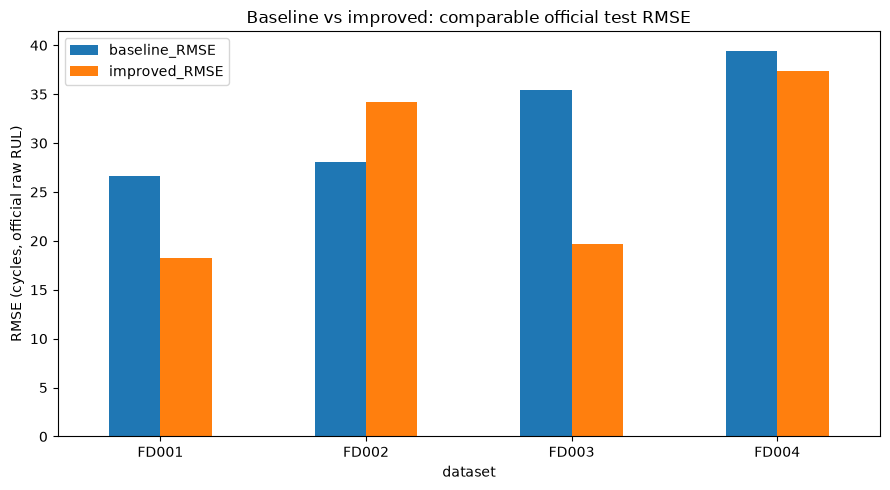

In [7]:
comparison = []
for ds in DATASETS:
    old_path = METRICS_DIR / f"{ds.lower()}_test_metrics.csv"
    # Alternative location if original files are held at project root.
    if not old_path.exists():
        old_path = PROJECT_ROOT / f"{ds.lower()}_test_metrics.csv"
    new = test_results[(test_results.dataset == ds) & (test_results.target == "official raw RUL")].iloc[0]
    if old_path.exists():
        old = pd.read_csv(old_path).iloc[0]
        comparison.append({"dataset": ds, "baseline_RMSE": float(old["RMSE"]),
                           "improved_RMSE": new["RMSE"],
                           "RMSE_improvement_pct": 100 * (float(old["RMSE"]) - new["RMSE"]) / float(old["RMSE"]),
                           "baseline_MAE": float(old["MAE"]), "improved_MAE": new["MAE"]})
    else:
        print(f"No saved baseline test metrics for {ds}: {old_path}")
comparison = pd.DataFrame(comparison)
if not comparison.empty:
    display(comparison.round(2))
    comparison.to_csv(METRICS_DIR / "baseline_vs_improved_RUL.csv", index=False)
    ax = comparison.set_index("dataset")[["baseline_RMSE", "improved_RMSE"]].plot.bar(figsize=(9,5))
    ax.set_ylabel("RMSE (cycles, official raw RUL)")
    ax.set_title("Baseline vs improved: comparable official test RMSE")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "baseline_vs_improved_rmse.png", dpi=200)
    plt.show()


,dataset,RUL_band,engines,MAE,mean_signed_error
0,FD001,0–30,25,5.44,4.69
1,FD001,31–60,14,6.27,3.38
2,FD001,61–100,28,9.47,-2.64
3,FD001,101–150,33,25.83,-25.83
4,FD002,0–30,61,7.50,5.71
5,FD002,31–60,41,12.30,8.38
6,FD002,61–100,65,11.60,-2.19
7,FD002,101–150,56,30.36,-30.36
8,FD002,151+,36,74.91,-74.91
9,FD003,0–30,20,3.86,3.23


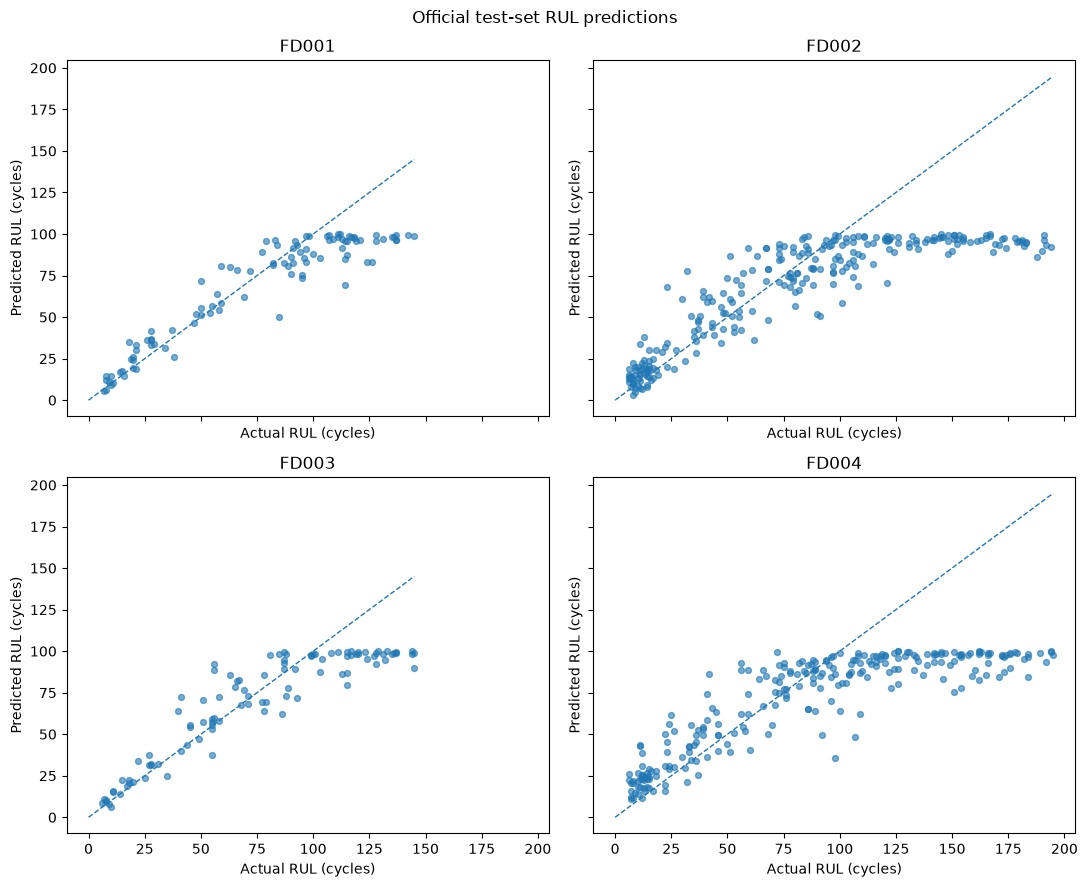

In [8]:
bins = [-1, 30, 60, 100, 150, np.inf]
labels = ["0–30", "31–60", "61–100", "101–150", "151+"]
predictions_all["RUL_band"] = pd.cut(predictions_all.actual_RUL, bins=bins, labels=labels)
band_results = (predictions_all.groupby(["dataset", "RUL_band"], observed=True)
                .agg(engines=("engine_id", "count"),
                     MAE=("absolute_error_raw", "mean"),
                     mean_signed_error=("error_raw", "mean")).reset_index())
display(band_results.round(2))
band_results.to_csv(METRICS_DIR / "improved_errors_by_rul_range.csv", index=False)

fig, axes = plt.subplots(2, 2, figsize=(11, 9), sharex=True, sharey=True)
for ax, ds in zip(axes.flat, DATASETS):
    sub = predictions_all[predictions_all.dataset == ds]
    ax.scatter(sub.actual_RUL, sub.predicted_RUL, alpha=.6, s=18)
    limit = max(float(sub.actual_RUL.max()), float(sub.predicted_RUL.max()), 100)
    ax.plot([0, limit], [0, limit], "--", linewidth=1)
    ax.set(title=ds, xlabel="Actual RUL (cycles)", ylabel="Predicted RUL (cycles)")
fig.suptitle("Official test-set RUL predictions")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "improved_test_predictions_all_datasets.png", dpi=200)
plt.show()
